<a href="https://colab.research.google.com/github/Rohithummalla/United-States-Top-50-Playlist-Performance-and-Song-Popularity-Trend-Analysis/blob/main/United_States_Top_50_Playlist_Performance_and_Song_Popularity_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## Load datset and packages install

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/Atlantic_United_States.csv")

print("Shape:", df.shape)
print(df.head())
print(df.info())
print(df.describe(include="all"))

Shape: (27800, 10)
         date  position                         song  \
0  18-05-2024         1              Ella Baila Sola   
1  18-05-2024         2                   Last Night   
2  18-05-2024         3  All My Life (feat. J. Cole)   
3  18-05-2024         4                    un x100to   
4  18-05-2024         5                    Kill Bill   

                       artist  popularity  duration_ms album_type  \
0              Eslabon Armado          89       165671      album   
1               Morgan Wallen          89       163854      album   
2          Lil Durk & J. Cole          84       223878     single   
3  Grupo Frontera & Bad Bunny          99       194563     single   
4                         SZA          94       153946      album   

   total_tracks  is_explicit  \
0            16        False   
1            36         True   
2             1         True   
3             1        False   
4            23        False   

                                    

In [ ]:
## Covert date format is DD-MM-YYYY, so specify the format explicitly.

df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Invalid dates:", df["date"].isna().sum())


Date range: 2024-05-18 00:00:00 to 2025-11-27 00:00:00
Invalid dates: 0


In [ ]:
## Check missing values and duplicates

print("Missing values:")
print(df.isnull().sum())

print("Exact duplicates:", df.duplicated().sum())

print("Duplicate song-date records:")
print(df.duplicated(
    subset=["date", "song", "artist"]
).sum())

print("Duplicate date-position records:")
print(df.duplicated(
    subset=["date", "position"]
).sum())


Missing values:
date               0
position           0
song               0
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
dtype: int64
Exact duplicates: 10
Duplicate song-date records:
48
Duplicate date-position records:
50


In [ ]:
### Validate ranking and field values

print("Invalid ranks:",
      (~df["position"].between(1, 50)).sum())

print("Invalid popularity:",
      (~df["popularity"].between(0, 100)).sum())

print("Invalid duration:",
      (df["duration_ms"] <= 0).sum())

print("Album types:")
print(df["album_type"].value_counts())

print("Rows per date:")
print(df.groupby("date").size().sort_values(ascending=False).head(10))


Invalid ranks: 0
Invalid popularity: 0
Invalid duration: 0
Album types:
album_type
album          19742
single          8016
compilation       42
Name: count, dtype: int64
Rows per date:
date
2025-03-01    100
2025-05-20     50
2025-05-21     50
2025-05-22     50
2025-05-23     50
2025-05-24     50
2025-05-25     50
2025-05-26     50
2025-05-02     50
2025-05-28     50
dtype: int64


In [ ]:
### cleaning dataset

import os

df = df.drop_duplicates().copy()

# Standardize text fields without changing song meaning
for col in ["song", "artist", "album_type"]:
    df[col] = df[col].astype("string").str.strip()

# Create an analysis-friendly duration column
df["duration_min"] = df["duration_ms"] / 60000

# Ensure output directory exists before saving
os.makedirs("outputs", exist_ok=True)

# Export an initial cleaned version
df.to_csv("outputs/cleaned_data.csv", index=False)

print("Rows after exact deduplication:", len(df))

Rows after exact deduplication: 27790


        date  total_rows  unique_songs  average_popularity  average_rank
0 2024-05-18          50            50               90.06          25.5
1 2024-05-19          50            50               90.00          25.5
2 2024-05-20          50            50               90.04          25.5
3 2024-05-21          50            50               88.68          25.5
4 2024-05-22          50            50               88.16          25.5


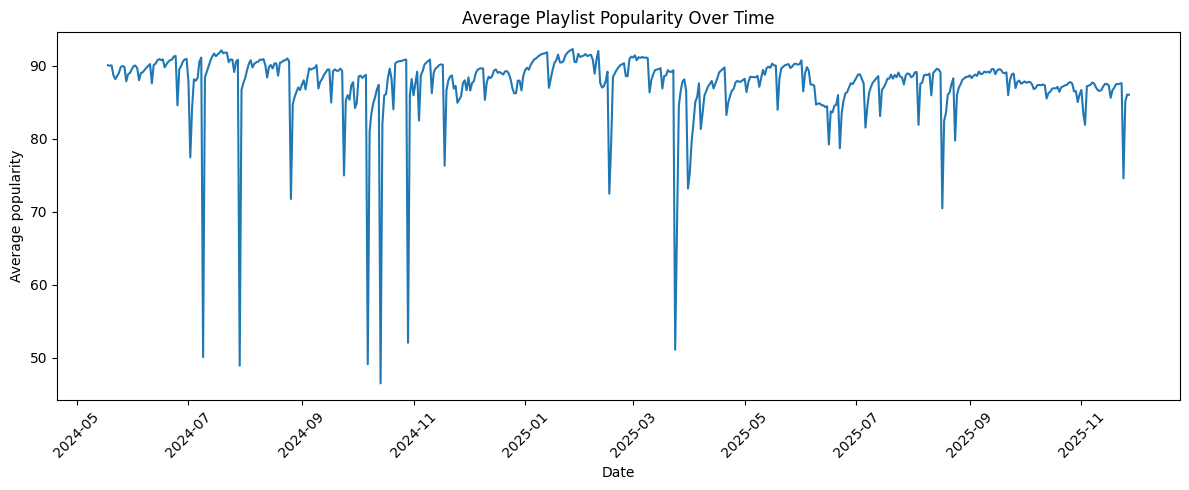

In [ ]:
''' Perform exploratory data analysis (EDA)'''

 ### Does every date have 50 songs?
 ## What is the average popularity of each daily Top 50?
 ### How many unique songs appear each day?
 ### Are there unusual dates with duplicate positions or missing ranks?



daily_summary = df.groupby("date").agg(
    total_rows=("song", "size"),
    unique_songs=("song", "nunique"),
    average_popularity=("popularity", "mean"),
    average_rank=("position", "mean")
).reset_index()

print(daily_summary.head())

plt.figure(figsize=(12, 5))
plt.plot(
    daily_summary["date"],
    daily_summary["average_popularity"]
)
plt.title("Average Playlist Popularity Over Time")
plt.xlabel("Date")
plt.ylabel("Average popularity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




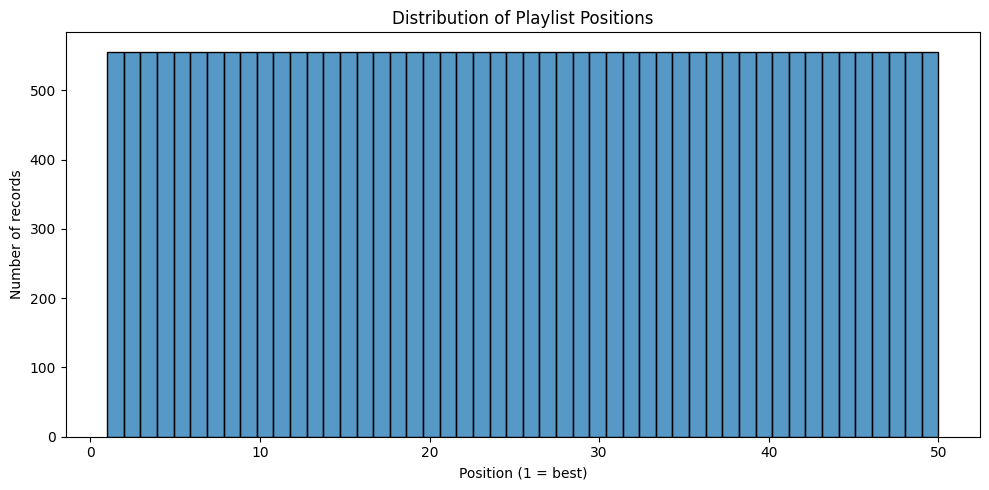

In [ ]:
### Analyze the rank distribution


plt.figure(figsize=(10, 5))
sns.histplot(df["position"], bins=50)
plt.title("Distribution of Playlist Positions")
plt.xlabel("Position (1 = best)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


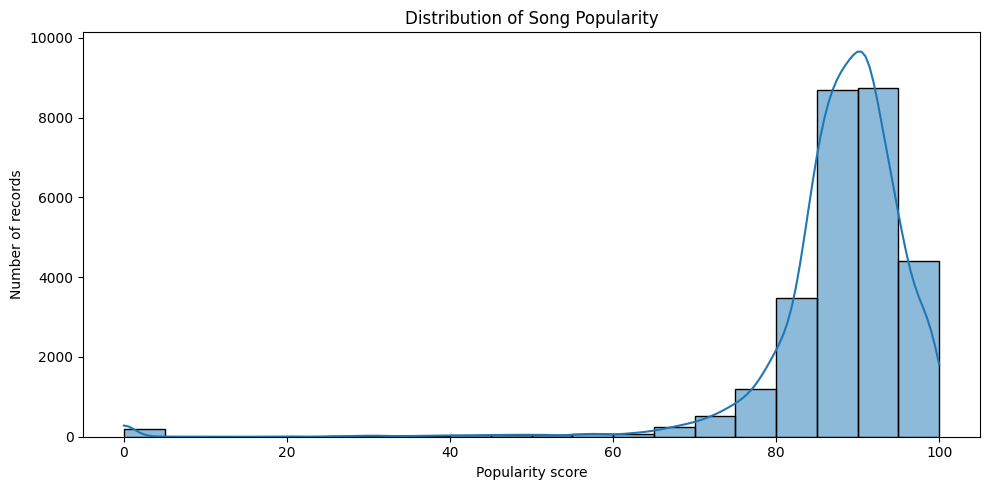

In [ ]:
 ###  Analyze popularity

plt.figure(figsize=(10, 5))
sns.histplot(df["popularity"], bins=20, kde=True)
plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity score")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()





In [ ]:
 '''Identify entry and exit behavior
Compare the songs appearing on consecutive snapshot dates.'''


daily_songs = {
    date: set(group["song"] + " | " + group["artist"])
    for date, group in df.groupby("date")
}

dates = sorted(daily_songs)
movement = []

for previous, current in zip(dates, dates[1:]):
    old = daily_songs[previous]
    new = daily_songs[current]

    movement.append({
        "date": current,
        "entries": len(new - old),
        "exits": len(old - new),
        "retained": len(old & new)
    })

movement_df = pd.DataFrame(movement)
print(movement_df.head())


        date  entries  exits  retained
0 2024-05-19        2      2        48
1 2024-05-20        0      0        50
2 2024-05-21        4      4        46
3 2024-05-22        2      2        48
4 2024-05-23        1      1        49


In [ ]:
 ####  Create the required KPIs
## Days on chart, average rank and best rank
''' define days on chart as the number of distinct snapshot dates on which a song appears. This avoids inflating the metric if duplicate records exist.'''


song_metrics = df.groupby(["song", "artist"]).agg(
    days_on_chart=("date", "nunique"),
    average_rank=("position", "mean"),
    best_rank=("position", "min"),
    worst_rank=("position", "max"),
    average_popularity=("popularity", "mean"),
    peak_popularity=("popularity", "max"),
    average_duration_min=("duration_min", "mean"),
    explicit_share=("is_explicit", "mean")
).reset_index()

print(
    song_metrics.sort_values(
        "days_on_chart", ascending=False
    ).head(10)
)


                                              song              artist  \
696                        Something in the Orange          Zach Bryan   
427                                     Last Night       Morgan Wallen   
364  I Remember Everything (feat. Kacey Musgraves)          Zach Bryan   
659               See You Again (feat. Kali Uchis)  Tyler, The Creator   
709                                   Stick Season          Noah Kahan   
170                                   Cruel Summer        Taylor Swift   
444                                   Lose Control         Teddy Swims   
790                               Thinkin’ Bout Me       Morgan Wallen   
99                                Beautiful Things        Benson Boone   
884                                      You Proof       Morgan Wallen   

     days_on_chart  average_rank  best_rank  worst_rank  average_popularity  \
696            536     26.284916          9          49           88.376164   
427            492     22.6

In [ ]:
#### Calculate rank volatility and popularity trends


song_metrics["rank_volatility"] = (
    df.groupby(["song", "artist"])["position"]
      .std()
      .fillna(0)
      .to_numpy()
)

df = df.sort_values(["song", "artist", "date"]).copy()

df["popularity_7_snapshot_avg"] = (
    df.groupby(["song", "artist"])["popularity"]
      .transform(lambda s: s.rolling(7, min_periods=1).mean())
)

df["rank_change"] = (
    df.groupby(["song", "artist"])["position"]
      .diff()
)

print(song_metrics.head())


                                                song            artist  \
0        "Slut!" (Taylor's Version) (From The Vault)      Taylor Swift   
1                            (Don't Fear) The Reaper  Blue Öyster Cult   
2  (There's No Place Like) Home for the Holidays ...        Perry Como   
3                                       16 CARRIAGES           Beyoncé   
4                                            2 hands        Tate McRae   

   days_on_chart  average_rank  best_rank  worst_rank  average_popularity  \
0             26     15.500000          3          38           86.769231   
1              1     50.000000         50          50           77.000000   
2              2     45.000000         45          45           70.000000   
3             10     26.000000         16          49           64.500000   
4              7     33.571429          8          45           76.571429   

   peak_popularity  average_duration_min  explicit_share  rank_volatility  
0               

In [ ]:
### Create the artist leaderboard


artist_metrics = df.groupby("artist").agg(
    unique_songs=("song", "nunique"),
    total_song_date_records=("date", "size"),
    active_snapshot_dates=("date", "nunique"),
    average_rank=("position", "mean"),
    average_popularity=("popularity", "mean")
).reset_index()

artist_metrics = artist_metrics.sort_values(
    ["active_snapshot_dates", "unique_songs"],
    ascending=False
)

print(artist_metrics.head(10))


                 artist  unique_songs  total_song_date_records  \
286          Zach Bryan            35                     1860   
177       Morgan Wallen            10                     1672   
273  Tyler, The Creator            16                      706   
242        Taylor Swift            96                     2015   
188          Noah Kahan             8                      450   
227                 SZA             3                      649   
161          Luke Combs             6                      371   
22        Billie Eilish            12                      729   
266        Travis Scott            31                      764   
243         Teddy Swims             1                      329   

     active_snapshot_dates  average_rank  average_popularity  
286                    546     25.613978           86.038172  
177                    540     30.611842           85.410287  
273                    445     25.291785           88.399433  
242                  

In [ ]:
 ### Use these comparisons:
'''Attribute	Analysis
Explicit content	Compare average popularity and rank for explicit vs non-explicit songs
Album type	Compare single, album and compilation tracks
Duration	Compare song length with popularity and rank
Album size	Compare total_tracks with popularity and chart persistence
Popularity vs rank	Measure the relationship between popularity and playlist position'''

print(df.groupby("is_explicit").agg(
    records=("song", "size"),
    average_popularity=("popularity", "mean"),
    average_rank=("position", "mean")
))

print(df.groupby("album_type").agg(
    records=("song", "size"),
    average_popularity=("popularity", "mean"),
    average_rank=("position", "mean")
))

print("Popularity-rank correlation:",
      df["popularity"].corr(df["position"]))


             records  average_popularity  average_rank
is_explicit                                           
False          14461           87.989143      25.59823
True           13329           87.310376      25.40138
             records  average_popularity  average_rank
album_type                                            
album          19735           86.680263     26.105244
compilation       42           78.380952     33.190476
single          8013           90.134032     23.982279
Popularity-rank correlation: -0.09452757402937857


In [ ]:
 '''' checking dataset wheather its cleaned or Not '''

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nPopularity range:")
print(df["popularity"].min(), df["popularity"].max())


Dataset shape: (27790, 13)

Missing values:
date                           0
position                       0
song                           0
artist                         0
popularity                     0
duration_ms                    0
album_type                     0
total_tracks                   0
is_explicit                    0
album_cover_url                0
duration_min                   0
popularity_7_snapshot_avg      0
rank_change                  977
dtype: int64

Duplicate rows: 0

Column data types:
date                         datetime64[ns]
position                              int64
song                         string[python]
artist                       string[python]
popularity                            int64
duration_ms                           int64
album_type                   string[python]
total_tracks                          int64
is_explicit                            bool
album_cover_url                      object
duration_min                       